In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [2]:
# import data

# growth
ATPvsGrowth_model8 = pd.read_csv('csvs/ATPvsGrowth_model8.csv')
ATPvsGrowth_model11 = pd.read_csv('csvs/ATPvsGrowth_model11.csv')

# glucose
ATPvsGlucose_model8 = pd.read_csv('csvs/ATPvsGlucose_model8.csv')
ATPvsGlucose_model11 = pd.read_csv('csvs/ATPvsGlucose_model11.csv')

# oxygen
ATPvsOxygen_model8 = pd.read_csv('csvs/ATPvsOxygen_model8.csv')
ATPvsOxygen_model11 = pd.read_csv('csvs/ATPvsOxygen_model11.csv')

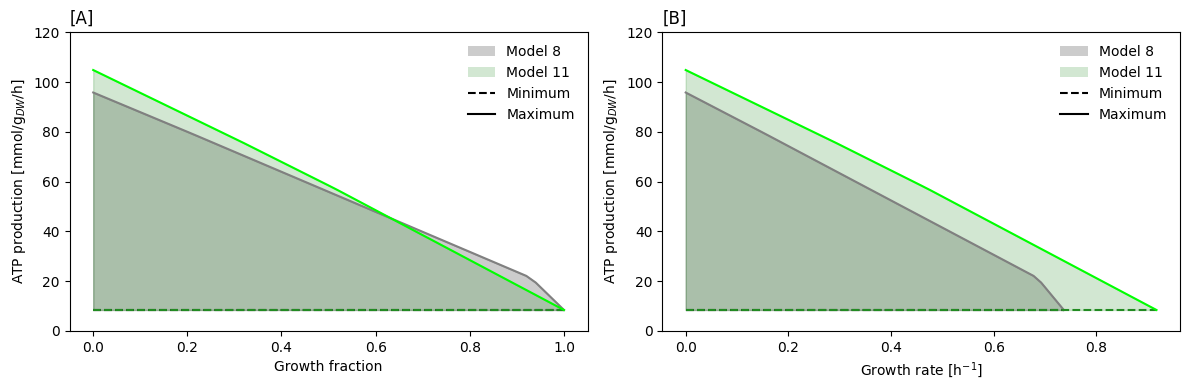

In [ ]:
# ATPvsGrowth plots
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

legend_elements = [
    Patch(facecolor='0', alpha=0.2, label='Model 8'),
    Patch(facecolor='forestgreen', alpha=0.2, label='Model 11'),
    Line2D([0], [0], color='k', linestyle='--', label='Minimum'),
    Line2D([0], [0], color='k', linestyle='-', label='Maximum')
]

# ---- subplot 1: percent vs growth ----
axs[0].plot(ATPvsGrowth_model8['GrowthFraction'], ATPvsGrowth_model8['ATPmin'], linestyle='--', color='0', label="Minimum ATPM (Model 8)")
axs[0].plot(ATPvsGrowth_model8['GrowthFraction'], ATPvsGrowth_model8['ATPmax'], linestyle='-', color='0.5', label="Maximum ATPM (Model 8)")

fill = axs[0].fill_between(
    ATPvsGrowth_model8['GrowthFraction'],
    ATPvsGrowth_model8['ATPmin'],
    ATPvsGrowth_model8['ATPmax'],
    color='0',
    alpha=0.2,
    label='Feasible ATPM range'
)

axs[0].plot(ATPvsGrowth_model11['GrowthFraction'], ATPvsGrowth_model11['ATPmin'], linestyle='--', color='forestgreen', label="Minimum ATPM (Model 11)")
axs[0].plot(ATPvsGrowth_model11['GrowthFraction'], ATPvsGrowth_model11['ATPmax'], linestyle='-', color='lime', label="Maximum ATPM (Model 11)")

fill = axs[0].fill_between(
    ATPvsGrowth_model11['GrowthFraction'],
    ATPvsGrowth_model11['ATPmin'],
    ATPvsGrowth_model11['ATPmax'],
    color='forestgreen',
    alpha=0.2,
    label='Feasible ATPM range'
)

axs[0].set_xlabel("Growth fraction") # relative to µ max
axs[0].set_ylabel("ATP production [mmol/g$_{DW}$/h]")
axs[0].set_ylim(0, 120)
axs[0].set_title("[A]", loc="left") # ATP Maximization at Different Growth Constraints
axs[0].legend(handles=legend_elements, frameon=False)

# ---- subplot 2: percent*mu vs growth ----
axs[1].plot(ATPvsGrowth_model8['GrowthRate'], ATPvsGrowth_model8['ATPmin'], linestyle='--', color='0', label="Minimum ATPM (Model 8)")
axs[1].plot(ATPvsGrowth_model8['GrowthRate'], ATPvsGrowth_model8['ATPmax'], linestyle='-', color='0.5', label="Maximum ATPM (Model 8)")

fill = axs[1].fill_between(
    ATPvsGrowth_model8['GrowthRate'],
    ATPvsGrowth_model8['ATPmin'],
    ATPvsGrowth_model8['ATPmax'],
    color='0',
    alpha=0.2,
    label='Feasible ATPM range'
)

axs[1].plot(ATPvsGrowth_model11['GrowthRate'], ATPvsGrowth_model11['ATPmin'], linestyle='--', color='forestgreen', label="Minimum ATPM (Model 11)")
axs[1].plot(ATPvsGrowth_model11['GrowthRate'], ATPvsGrowth_model11['ATPmax'], linestyle='-', color='lime', label="Maximum ATPM (Model 11)")

fill = axs[1].fill_between(
    ATPvsGrowth_model11['GrowthRate'],
    ATPvsGrowth_model11['ATPmin'],
    ATPvsGrowth_model11['ATPmax'],
    color='forestgreen',
    alpha=0.2,
    )

axs[1].set_xlabel('Growth rate [h$^{-1}$]') # relative to µ max
axs[1].set_ylabel("ATP production [mmol/g$_{DW}$/h]")
axs[1].set_ylim(0, 120)
axs[1].set_title("[B]", loc="left")
axs[1].legend(handles=legend_elements, frameon=False)

plt.tight_layout()
plt.savefig("ATPvsGrowth.png", dpi=300, bbox_inches="tight")
plt.show()

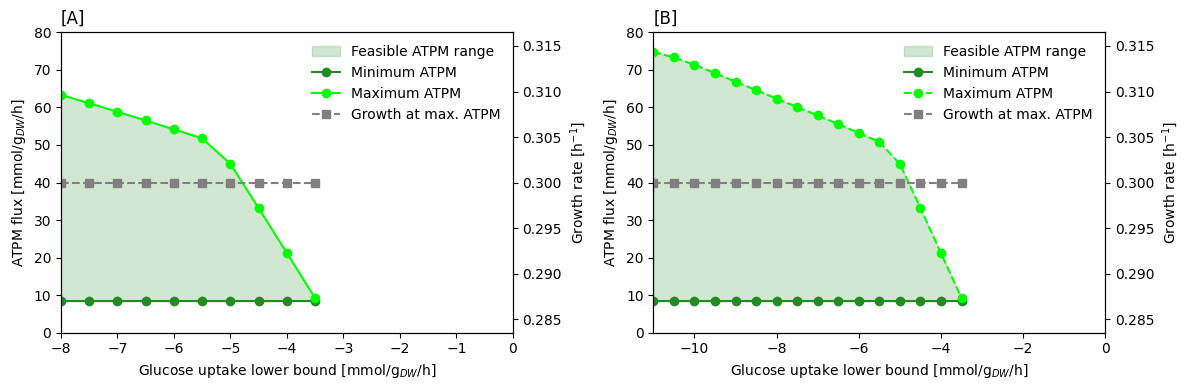

In [14]:
# ATPvsGlucose plots
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# ---------- subplot 1: Model 8 ----------
ax = axs[0]
ax2 = ax.twinx()

l1 = ax.plot(ATPvsGlucose_model8['GlucoseLowerBound'], ATPvsGlucose_model8['ATPminimum'], marker="o",  color='forestgreen', label="Minimum ATPM")
l2 = ax.plot(ATPvsGlucose_model8['GlucoseLowerBound'],  ATPvsGlucose_model8['ATPmaximum'], marker="o",  color='lime', label="Maximum ATPM")
l3 = ax2.plot(ATPvsGlucose_model8['GlucoseLowerBound'], ATPvsGlucose_model8['GrowthAtATPmaximum'], marker="s",  color='0.5', linestyle="--", label="Growth at max. ATPM")

fill = ax.fill_between(
    ATPvsGlucose_model8['GlucoseLowerBound'],
    ATPvsGlucose_model8['ATPminimum'],
    ATPvsGlucose_model8['ATPmaximum'],
    color='forestgreen',
    alpha=0.2,
    label='Feasible ATPM range'
)

ax.set_xlim(-8, 0)
ax.set_xlabel("Glucose uptake lower bound [mmol/g$_{DW}$/h]")
ax.set_ylim(0, 80)
ax.set_ylabel("ATPM flux [mmol/g$_{DW}$/h]")
ax2.set_ylabel("Growth rate [h$^{-1}$]")

ax.set_title("[A]", loc='left') # Model 8: ATP & Growth vs Glucose uptake

lines = [fill] + l1 + l2 + l3
labels = [h.get_label() for h in lines]
ax.legend(lines, labels, frameon=False)


# ---------- subplot 2: Model 11 ----------
ax = axs[1]
ax2 = ax.twinx()

l1 = ax.plot(ATPvsGlucose_model11['GlucoseLowerBound'], ATPvsGlucose_model11['ATPminimum'], marker="o", color='forestgreen', label="Minimum ATPM")
l2 = ax.plot(ATPvsGlucose_model11['GlucoseLowerBound'], ATPvsGlucose_model11['ATPmaximum'], marker="o",color='lime', linestyle="--", label="Maximum ATPM")
l3 = ax2.plot(ATPvsGlucose_model11['GlucoseLowerBound'], ATPvsGlucose_model11['GrowthAtATPmaximum'], marker="s",  color='0.5', linestyle="--", label="Growth at max. ATPM")

fill = ax.fill_between(
    ATPvsGlucose_model11['GlucoseLowerBound'],
    ATPvsGlucose_model11['ATPminimum'],
    ATPvsGlucose_model11['ATPmaximum'],
    color='forestgreen',
    alpha=0.2,
    label='Feasible ATPM range'
)

ax.set_xlim(-11, 0)
ax.set_xlabel("Glucose uptake lower bound [mmol/g$_{DW}$/h]")
ax.set_ylim(0, 80)
ax.set_ylabel("ATPM flux [mmol/g$_{DW}$/h]")
ax2.set_ylabel("Growth rate [h$^{-1}$]")

ax.set_title("[B]", loc='left')

lines = [fill] + l1 + l2 + l3
labels = [h.get_label() for h in lines]
ax.legend(lines, labels, frameon=False)

plt.tight_layout()
plt.savefig("ATPvsGlucose.png", dpi=300, bbox_inches="tight")
plt.show()

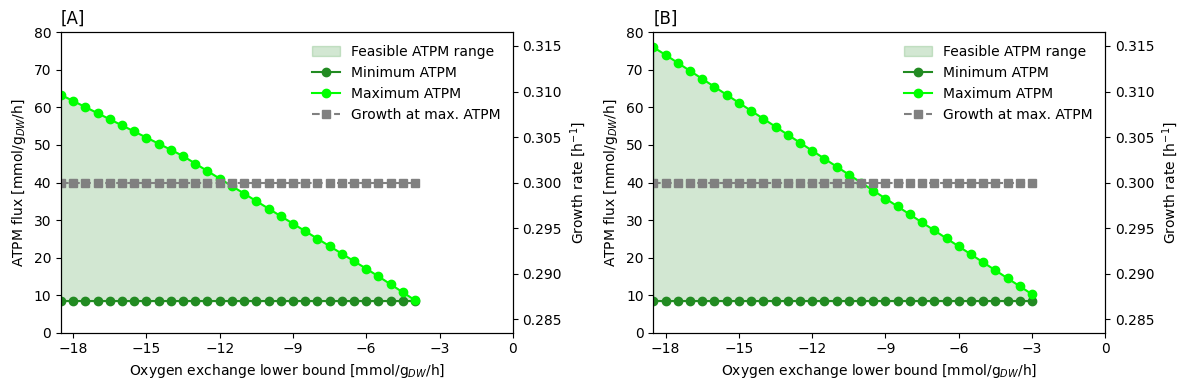

In [ ]:
# ATPvsOxygen plots
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# ---------- subplot 1: Model 8 ----------
ax = axs[0]
ax2 = ax.twinx()

l1 = ax.plot(ATPvsOxygen_model8['OxygenLowerBound'], ATPvsOxygen_model8['ATPminimum'], marker="o", color='forestgreen', label="Minimum ATPM")
l2 = ax.plot(ATPvsOxygen_model8['OxygenLowerBound'], ATPvsOxygen_model8['ATPmaximum'], marker="o", color='lime', label="Maximum ATPM")
l3 = ax2.plot(ATPvsOxygen_model8['OxygenLowerBound'], ATPvsOxygen_model8['GrowthAtATPmaximum'], marker="s", color='0.5', linestyle="--", label="Growth at max. ATPM")

fill = ax.fill_between(
    ATPvsOxygen_model8['OxygenLowerBound'],
    ATPvsOxygen_model8['ATPminimum'],
    ATPvsOxygen_model8['ATPmaximum'],
    color='forestgreen',
    alpha=0.2,
    label='Feasible ATPM range'
)

ax.set_xticks([-18,-15, -12, -9, -6, -3, 0])
ax.set_xlim(-18.5, 0)
ax.set_xlabel("Oxygen exchange lower bound [mmol/g$_{DW}$/h]")
ax.set_ylim(0, 80)
ax.set_ylabel("ATPM flux [mmol/g$_{DW}$/h]")
ax2.set_ylabel("Growth rate [h$^{-1}$]")

ax.set_title("[A]", loc='left') # Model 8: ATP & Growth vs Oxygen uptake

lines = [fill] + l1 + l2 + l3
labels = [h.get_label() for h in lines]
ax.legend(lines, labels, frameon=False)

# ---------- subplot 2: Model 11 ----------
ax = axs[1]
ax2 = ax.twinx()

l1 = ax.plot(ATPvsOxygen_model11['OxygenLowerBound'], ATPvsOxygen_model11['ATPminimum'], marker="o", color='forestgreen', label="Minimum ATPM")
l2 = ax.plot(ATPvsOxygen_model11['OxygenLowerBound'], ATPvsOxygen_model11['ATPmaximum'], marker="o", color='lime', label="Maximum ATPM")
l3 = ax2.plot(ATPvsOxygen_model11['OxygenLowerBound'], ATPvsOxygen_model11['GrowthAtATPmaximum'], marker="s", color='0.5', linestyle="--", label="Growth at max. ATPM")

fill = ax.fill_between(
    ATPvsOxygen_model11['OxygenLowerBound'],
    ATPvsOxygen_model11['ATPminimum'],
    ATPvsOxygen_model11['ATPmaximum'],
    color='forestgreen',
    alpha=0.2,
    label='Feasible ATPM range'
)

ax.set_xlim(-18.5, 0)
ax.set_xticks([-18,-15, -12, -9, -6, -3, 0])
ax.set_xlabel("Oxygen exchange lower bound [mmol/g$_{DW}$/h]")
ax.set_ylim(0, 80)
ax.set_ylabel("ATPM flux [mmol/g$_{DW}$/h]")
ax2.set_ylabel("Growth rate [h$^{-1}$]")

ax.set_title("[B]", loc='left')

lines = [fill] + l1 + l2 + l3
labels = [h.get_label() for h in lines]
ax.legend(lines, labels, frameon=False)

plt.tight_layout()
plt.savefig("ATPvsOxygen.png", dpi=300, bbox_inches="tight")
plt.show()